# Fine-tuned RoBERTa for ternary AI-text detection

Third rung of the comparison ladder: **TF-IDF + LR**, then **frozen RoBERTa + LR**, then **fine-tuned `roberta-base`** (this notebook).

Protocol (identical data handling to the two baselines):
1. Load `ternary_academic_wiki_512.csv` (English academic + wiki, 512-token truncated).
2. Keep the supplied `test` split untouched. Split the supplied `train` partition into fit / validation grouped by `pair_id` (seed 42, 15%).
3. Fine-tune all RoBERTa weights plus a classification head on the fit split. Select the best epoch by **validation macro-F1**.
4. Evaluate on the supplied test split **once**.
5. Error analysis, a formatting-shortcut robustness check, and a side-by-side comparison with the two baselines.

Runtime: select **Runtime > Change runtime type > T4 GPU**.

In [ ]:
!pip -q install transformers accelerate scikit-learn pandas matplotlib

In [4]:
import os, re, math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, set_seed
)

# ---- configuration ----
SEED = 42
VAL_SIZE = 0.15
DATA_PATH = 'ternary_academic_wiki_512.csv'
MODEL_NAME = 'roberta-base'
MAX_LENGTH = 512
LR = 2e-5
EPOCHS = 3
TRAIN_BS = 16
EVAL_BS = 64
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.1
OUTPUT_DIR = 'roberta_ft_out'

LABELS = ['human', 'ai_generated', 'ai_refined']
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

set_seed(SEED)
print('CUDA available:', torch.cuda.is_available())

CUDA available: True


## 1. Load data and rebuild the identical pair-safe split

If the CSV is not in the session, upload the one created by the RoBERTa baseline notebook so all three models use exactly the same texts.

In [ ]:
if not os.path.exists(DATA_PATH):
    from google.colab import files
    print(f'{DATA_PATH} not found. Upload it now.')
    files.upload()

df = pd.read_csv(DATA_PATH)
required = {'text', 'label', 'pair_id', 'lang', 'model', 'domain', 'split'}
missing = required - set(df.columns)
assert not missing, f'Missing columns: {missing}'

df = df.dropna(subset=['text', 'label', 'pair_id']).copy()
df['text'] = df['text'].astype(str)
df['label'] = df['label'].astype(str)
df['pair_id'] = df['pair_id'].astype(str)
df['split'] = df['split'].astype(str).str.lower()
assert set(df['label']) <= set(LABELS), f'Unexpected labels: {set(df["label"]) - set(LABELS)}'

train_all = df[df['split'] == 'train'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)
assert len(train_all) > 0 and len(test_df) > 0

gss = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)
fit_idx, val_idx = next(gss.split(train_all, groups=train_all['pair_id']))
fit_df = train_all.iloc[fit_idx].reset_index(drop=True)
val_df = train_all.iloc[val_idx].reset_index(drop=True)

assert set(fit_df['pair_id']).isdisjoint(val_df['pair_id'])
assert set(fit_df['pair_id']).isdisjoint(test_df['pair_id'])
assert set(val_df['pair_id']).isdisjoint(test_df['pair_id'])

for name, part in [('fit', fit_df), ('validation', val_df), ('test', test_df)]:
    n_pairs = part['pair_id'].nunique()
    print(f'{name}: {len(part):,} texts, {n_pairs:,} pairs')
    display(part['label'].value_counts())

fit: 5,100 texts, 1,700 pairs


,count
label,
human,1700
ai_generated,1700
ai_refined,1700


validation: 900 texts, 300 pairs


,count
label,
human,300
ai_generated,300
ai_refined,300


test: 1,500 texts, 500 pairs


,count
label,
human,500
ai_generated,500
ai_refined,500


## 2. Tokenize

Texts are tokenized once without padding; `DataCollatorWithPadding` pads each batch to its longest sequence.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class TextClsDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)
        self.labels = [label2id[l] for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = self.labels[i]
        return item

train_ds = TextClsDataset(fit_df['text'], fit_df['label'])
val_ds = TextClsDataset(val_df['text'], val_df['label'])
test_ds = TextClsDataset(test_df['text'], test_df['label'])
print(len(train_ds), len(val_ds), len(test_ds))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

5100 900 1500


## 3. Model and training setup

- Learning rate 2e-5, 3 epochs, batch size 16, 10% linear warmup, weight decay 0.01 (standard RoBERTa fine-tuning defaults).
- Evaluate and checkpoint every epoch; the checkpoint with the best **validation macro-F1** is restored at the end.
- Mixed precision (fp16) is enabled automatically on GPU.
- The classes are balanced, so no class weights are used.

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
    }

steps_per_epoch = math.ceil(len(train_ds) / TRAIN_BS)
warmup_steps = int(WARMUP_FRAC * steps_per_epoch * EPOCHS)

args_kwargs = dict(
    output_dir=OUTPUT_DIR,
    learning_rate=LR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BS,
    per_device_eval_batch_size=EVAL_BS,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=warmup_steps,
    save_strategy='epoch',
    logging_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to='none',
)
try:
    training_args = TrainingArguments(eval_strategy='epoch', **args_kwargs)
except TypeError:   # older transformers versions
    training_args = TrainingArguments(evaluation_strategy='epoch', **args_kwargs)

trainer_kwargs = dict(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
try:
    trainer = Trainer(processing_class=tokenizer, **trainer_kwargs)
except TypeError:   # older transformers versions
    trainer = Trainer(tokenizer=tokenizer, **trainer_kwargs)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 4. Train

In [ ]:
train_output = trainer.train()
print('Training done. Final train loss:', round(train_output.training_loss, 4))

log = pd.DataFrame(trainer.state.log_history)
cols = [c for c in ['epoch', 'loss', 'eval_loss', 'eval_accuracy', 'eval_macro_f1'] if c in log.columns]
display(log[cols].groupby('epoch').first().round(4))
print('Best checkpoint:', trainer.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.413078,0.182925,0.963333,0.963367
2,0.096584,0.200826,0.958889,0.958785
3,0.040074,0.210306,0.965556,0.965490


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training done. Final train loss: 0.1832


,loss,eval_loss,eval_accuracy,eval_macro_f1
epoch,,,,
1.0,0.4131,0.1829,0.9633,0.9634
2.0,0.0966,0.2008,0.9589,0.9588
3.0,0.0401,0.2103,0.9656,0.9655


Best checkpoint: roberta_ft_out/checkpoint-957


## 5. Validation results (best epoch)

Validation accuracy: 0.9656
Validation macro-F1: 0.9655
              precision    recall  f1-score   support

       human     0.9859    0.9333    0.9589       300
ai_generated     0.9772    1.0000    0.9885       300
  ai_refined     0.9353    0.9633    0.9491       300

    accuracy                         0.9656       900
   macro avg     0.9661    0.9656    0.9655       900
weighted avg     0.9661    0.9656    0.9655       900



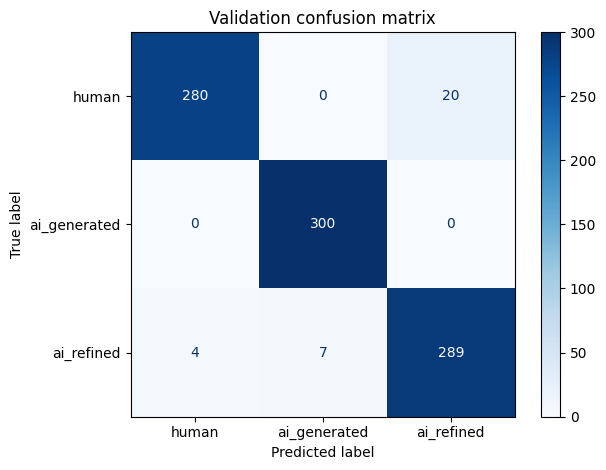

In [ ]:
def predict_ds(ds):
    out = trainer.predict(ds)
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
    pred = np.array([id2label[i] for i in probs.argmax(axis=1)])
    return pred, probs

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    mf1 = f1_score(y_true, y_pred, average='macro')
    print(f'{name} accuracy: {acc:.4f}')
    print(f'{name} macro-F1: {mf1:.4f}')
    print(classification_report(y_true, y_pred, labels=LABELS, digits=4, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=LABELS, display_labels=LABELS, cmap='Blues', values_format='d'
    )
    plt.title(f'{name} confusion matrix')
    plt.tight_layout()
    plt.show()
    return acc, mf1

val_pred, _ = predict_ds(val_ds)
_ = evaluate('Validation', val_df['label'].to_numpy(), val_pred)

## 6. Final evaluation on the held-out test split

Run this cell once, after you are done adjusting hyperparameters on validation. Re-running with different settings and picking the best test score would turn the test split into a second validation set.

Test accuracy: 0.9587
Test macro-F1: 0.9586
              precision    recall  f1-score   support

       human     0.9870    0.9120    0.9480       500
ai_generated     0.9766    1.0000    0.9881       500
  ai_refined     0.9163    0.9640    0.9396       500

    accuracy                         0.9587      1500
   macro avg     0.9600    0.9587    0.9586      1500
weighted avg     0.9600    0.9587    0.9586      1500



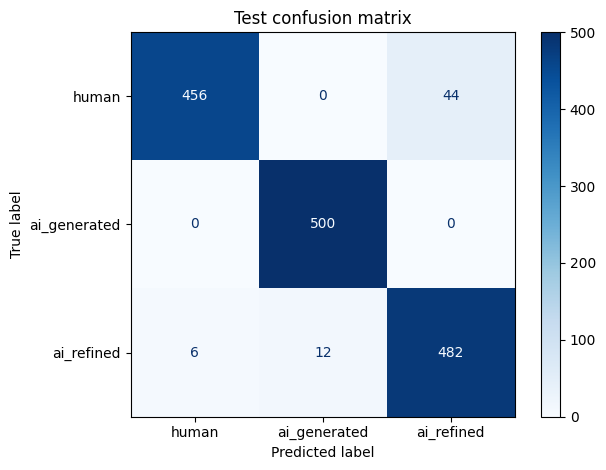

In [ ]:
test_pred, test_probs = predict_ds(test_ds)
test_acc, test_macro_f1 = evaluate('Test', test_df['label'].to_numpy(), test_pred)

## 7. Error analysis

In [ ]:
results = test_df.copy()
results['prediction'] = test_pred
results['correct'] = results['label'] == results['prediction']
for i, l in enumerate(LABELS):
    results[f'prob_{l}'] = test_probs[:, label2id[l]]
results['confidence'] = test_probs.max(axis=1)

print('Confusion counts (rows = true, columns = predicted):')
display(pd.crosstab(results['label'], results['prediction']))

print('Accuracy by domain:')
display(results.groupby('domain')['correct'].agg(['count', 'mean']))
print('Accuracy by source LLM:')
display(results.groupby('model')['correct'].agg(['count', 'mean']).sort_values('mean'))

print('Mean confidence, correct vs incorrect:')
display(results.groupby('correct')['confidence'].mean().round(3))

print('Highest-confidence mistakes:')
display(results[~results['correct']].sort_values('confidence', ascending=False)[
    ['label', 'prediction', 'confidence', 'domain', 'model', 'pair_id', 'text']
].head(10))

Confusion counts (rows = true, columns = predicted):


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,500,0,0
ai_refined,12,482,6
human,0,44,456


Accuracy by domain:


,count,mean
domain,,
Academic,750,0.965333
Wiki,750,0.952000


Accuracy by source LLM:


,count,mean
model,,
gemini-2.5-flash,378,0.949735
qwen-max,372,0.954301
gpt-4o,372,0.962366
deepseek-v3,378,0.968254


Mean confidence, correct vs incorrect:


,confidence
correct,
False,0.938
True,0.998


Highest-confidence mistakes:


,label,prediction,confidence,domain,model,pair_id,text
1115,ai_refined,ai_generated,0.999779,Academic,gemini-2.5-flash,110902,"Advanced molecular techniques, like 16S rRNA g..."
1400,ai_refined,ai_generated,0.999757,Academic,deepseek-v3,111660,"Therefore, the fatwa nullified the limestone c..."
815,ai_refined,ai_generated,0.999742,Academic,qwen-max,109688,Postmodernists frequently mock the styles and ...
572,ai_refined,ai_generated,0.999701,Wiki,qwen-max,38782,Santa Maria Navarrese is a picturesque coastal...
1335,human,ai_refined,0.999398,Academic,gpt-4o,111573,This method is widely used in various industri...
972,human,ai_refined,0.999390,Academic,gemini-2.5-flash,110701,The security and orderly implementation of the...
468,human,ai_refined,0.999363,Wiki,gpt-4o,38216,The El Royale is a historic apartment complex ...
576,human,ai_refined,0.999350,Wiki,qwen-max,38784,"Parthenolecanium quercifex, the oak lecanium s..."
216,human,ai_refined,0.999303,Wiki,gemini-2.5-flash,37507,Charles-Louis Havas (5 July 1783 – 21 May 1858...
123,human,ai_refined,0.999289,Wiki,deepseek-v3,36940,"Word of God Christian Academy is a private, Ch..."


## 8. Formatting-shortcut robustness check

Some `ai_generated` texts begin with a repeated title and `ai_refined` texts often use markdown such as `*Title*`. A fine-tuned model can pick up such artifacts easily. Here the **already trained** model is re-evaluated on test texts with markdown characters and duplicated leading titles removed. A large drop in macro-F1 suggests the model relies on formatting rather than writing style. The normalisation is a simple heuristic, so treat the result as indicative, not proof.

Share of texts with each pattern, by true label:


,dup_title,has_asterisk,has_hash,n_words
label,,,,
ai_generated,0.18,0.002,0.00,282.290
ai_refined,0.00,0.196,0.02,252.944
human,0.00,0.014,0.00,295.522


Test (normalised text) accuracy: 0.9573
Test (normalised text) macro-F1: 0.9572
              precision    recall  f1-score   support

       human     0.9870    0.9120    0.9480       500
ai_generated     0.9728    1.0000    0.9862       500
  ai_refined     0.9160    0.9600    0.9375       500

    accuracy                         0.9573      1500
   macro avg     0.9586    0.9573    0.9572      1500
weighted avg     0.9586    0.9573    0.9572      1500



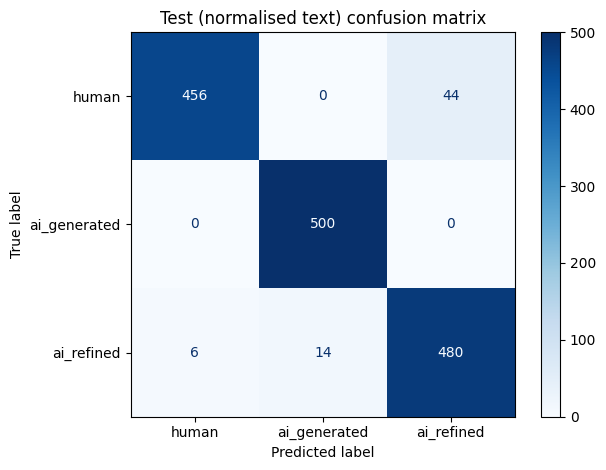

Macro-F1 change after normalisation: -0.0013


In [ ]:
DUP_START = re.compile(r'^\s*\x22?(.{3,100}?)\x22?\s+\x22?\1\x22?(?=\s|$)')

def has_dup_title(t):
    return bool(DUP_START.match(t))

def normalize_text(t):
    t = re.sub(r'[*#_`]+', ' ', t)
    t = t.replace(chr(34), ' ')
    t = re.sub(r'\s+', ' ', t).strip()
    return re.sub(r'^(.{3,100}?)\s+\1(?=\s|$)', r'\1', t)

stats = results.assign(
    dup_title=results['text'].map(has_dup_title),
    has_asterisk=results['text'].str.contains('*', regex=False),
    has_hash=results['text'].str.contains('#', regex=False),
    n_words=results['text'].str.split().str.len(),
)
print('Share of texts with each pattern, by true label:')
display(stats.groupby('label')[['dup_title', 'has_asterisk', 'has_hash', 'n_words']].mean().round(3))

norm_ds = TextClsDataset(test_df['text'].map(normalize_text), test_df['label'])
norm_pred, _ = predict_ds(norm_ds)
_, norm_macro_f1 = evaluate('Test (normalised text)', test_df['label'].to_numpy(), norm_pred)
print(f'Macro-F1 change after normalisation: {norm_macro_f1 - test_macro_f1:+.4f}')

## Prediction Samples

In [ ]:
import numpy as np
from IPython.display import display

#  QUALITATIVE ANALYSIS

results = results.copy()
results["word_count"] = (
    results["text"].fillna("").str.split().str.len()
)
results["correct"] = (
    results["label"] == results["prediction"]
)

# incorrect classifications

errors = results[~results["correct"]].copy()

selected_errors = []

for (actual, predicted), group in errors.groupby(
    ["label", "prediction"]
):
    # shortest incorrect example
    short = group.nsmallest(1, "word_count").copy()
    short["selection"] = "Shortest incorrect"

    # longest incorrect example
    long = group.drop(short.index).nlargest(
        1, "word_count"
    ).copy()
    long["selection"] = "Longest incorrect"

    # random incorrect example
    remaining = group.drop(
        short.index.union(long.index)
    )
    random_ex = remaining.sample(
        n=min(1, len(remaining)),
        random_state=43
    ).copy()
    random_ex["selection"] = "Random incorrect"

    selected_errors.extend([short, long, random_ex])

incorrect_examples = pd.concat(
    selected_errors, ignore_index=True
)

# correct classification

correct = results[results["correct"]].copy()

correct_examples = (
    correct.groupby("label", group_keys=False)
    .sample(n=1, random_state=43)
    .copy()
)

correct_examples["selection"] = "Random correct"

# combine & display

qualitative_examples = pd.concat(
    [incorrect_examples, correct_examples],
    ignore_index=True
)

for _, row in qualitative_examples.iterrows():
    print("\n" + "=" * 80)
    print("selection:", row["selection"])
    print("actual:", row["label"])
    print("predicted:", row["prediction"])
    print("domain:", row["domain"])
    print("model:", row["model"])
    print("ID:", row["pair_id"])
    print("word count:", row["word_count"])
    print("\nTEXT:")
    print(row["text"])


selection: Shortest incorrect
actual: ai_refined
predicted: ai_generated
domain: Wiki
model: qwen-max
ID: 38890
word count: 199

TEXT:
Bonnie Bremser, born Brenda Frazer in 1939, is a notable Beat writer and early feminist. She is best known for her epistolary memoir, "Troia: Mexican Memoirs, " also released in the U. K. as "For Love of Ray. " Born in Washington, D. C. , she briefly attended Sweet Briar College before eloping with Ray Bremser, whom she had known for only three weeks. In 1961, the couple, along with their baby, fled to Mexico due to Ray's parole violation. There, Bonnie was coerced into sex work by her husband. After Ray's imprisonment in 1963, Bonnie wrote him two-page letters weekly, detailing their life in Mexico and her experiences. These letters, presented as business correspondence to bypass jail restrictions, were later compiled into "Troia: Mexican Memoirs, " published in 1969. The title, "troia, " an Italian term meaning "sow" or "whore, " also alludes to Hele

## 9. Save predictions and the model

In [ ]:
results.to_csv('test_predictions_roberta_finetuned.csv', index=False)
trainer.save_model('roberta_finetuned_best')
tokenizer.save_pretrained('roberta_finetuned_best')

try:
    from google.colab import files
    files.download('test_predictions_roberta_finetuned.csv')
except ImportError:
    print('Not running in Colab; files are saved in the working directory.')

# Optional: zip the model folder (about 500 MB) if you want to keep it.
# !zip -rq roberta_finetuned_best.zip roberta_finetuned_best

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!zip -rq roberta_finetuned_best.zip roberta_finetuned_best

## 10. Compare fine-tuned with fixed-weights

Upload the prediction CSVs from the other two notebooks (`test_predictions_tfidf_lr.csv`, `test_predictions_roberta_frozen_lr.csv`) into this session.



In [5]:
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import textwrap

# ---- prediction files to compare (same truncation length for both) ----
FT_PATH = 'test_predictions_roberta_finetuned.csv'
FROZEN_PATH = 'test_predictions_roberta_frozen_lr.csv'


for p in (FT_PATH, FROZEN_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f'{p} not found.')


def load_pred(path):
    r = pd.read_csv(path)
    miss = {'text', 'label', 'prediction'} - set(r.columns)
    assert not miss, f'{path} is missing columns: {miss}'
    return r


ft = load_pred(FT_PATH)
fz = load_pred(FROZEN_PATH)
assert len(ft) == len(fz), (f'Different test sizes: fine-tuned {len(ft)} vs frozen {len(fz)}. '
                            'Were both run on the same data file?')
if 'max_length' in ft.columns:
    assert (ft['max_length'] == MAX_LENGTH).all(), 'Fine-tuned CSV was produced with a different MAX_LENGTH.'

ft_cols = [c for c in ['text', 'label', 'pair_id', 'domain', 'model', 'confidence'] if c in ft.columns]
same_order = ((ft['text'].to_numpy() == fz['text'].to_numpy()).all()
              and (ft['label'].to_numpy() == fz['label'].to_numpy()).all())
if same_order:
    cmp = ft[ft_cols].copy()
    cmp['pred_ft'] = ft['prediction'].to_numpy()
    cmp['pred_frozen'] = fz['prediction'].to_numpy()
else:
    key = ['text', 'label']
    assert not ft.duplicated(key).any() and not fz.duplicated(key).any(), \
        'Rows differ in order and texts are not unique, cannot align the two files.'
    cmp = (ft[ft_cols + ['prediction']].rename(columns={'prediction': 'pred_ft'})
           .merge(fz[key + ['prediction']].rename(columns={'prediction': 'pred_frozen'}),
                  on=key, how='inner', validate='one_to_one'))
    assert len(cmp) == len(ft), f'Only {len(cmp)} of {len(ft)} rows matched between the two files.'
cmp = cmp.rename(columns={'confidence': 'ft_confidence'}).reset_index(drop=True)

assert (set(cmp['pred_ft']) | set(cmp['pred_frozen'])) <= set(LABELS), 'Unexpected predicted labels.'
y = cmp['label'].to_numpy()
cmp['ft_correct'] = cmp['pred_ft'] == cmp['label']
cmp['frozen_correct'] = cmp['pred_frozen'] == cmp['label']
cmp['n_words'] = cmp['text'].str.split().str.len()

print(f'MAX_LENGTH = {MAX_LENGTH}')
print(f'fine-tuned file: {FT_PATH}')
print(f'frozen file:     {FROZEN_PATH}')
print(f'rows aligned: {len(cmp):,} (same row order: {same_order})')
print(f'identical predictions on {(cmp.pred_ft == cmp.pred_frozen).mean():.1%} of texts')
display(cmp['label'].value_counts().rename('test texts').to_frame().T)

MAX_LENGTH = 512
fine-tuned file: test_predictions_roberta_finetuned.csv
frozen file:     test_predictions_roberta_frozen_lr.csv
rows aligned: 1,500 (same row order: True)
identical predictions on 91.3% of texts


label,human,ai_generated,ai_refined
test texts,500,500,500


1. Overall


,accuracy,macro_f1,errors
Frozen RoBERTa + LR,0.9153,0.9158,127
Fine-tuned RoBERTa,0.9587,0.9586,62
Δ (fine-tuned − frozen),0.0433,0.0428,-65


2. Per class


frozen                fine-tuned                 \
             precision recall      f1  precision recall      f1   
human           0.9526  0.844  0.8950     0.9870  0.912  0.9480   
ai_generated    0.9776  0.960  0.9687     0.9766  1.000  0.9881   
ai_refined      0.8322  0.942  0.8837     0.9163  0.964  0.9396   

             Δ (ft − frozen)                support  
                   precision recall      f1       n  
human                 0.0344  0.068  0.0530     500  
ai_generated         -0.0010  0.040  0.0194     500  
ai_refined            0.0842  0.022  0.0559     500

3. Accuracy by domain


,n,frozen_acc,ft_acc,Δ (ft − frozen)
domain,,,,
Academic,750,0.9573,0.9653,0.0080
Wiki,750,0.8733,0.9520,0.0787


... (2 outputs left out)

5. Accuracy by source LLM


,n,frozen_acc,ft_acc,Δ (ft − frozen)
model,,,,
deepseek-v3,378,0.9286,0.9683,0.0397
gemini-2.5-flash,378,0.9021,0.9497,0.0476
gpt-4o,372,0.9274,0.9624,0.0349
qwen-max,372,0.9032,0.9543,0.0511


6. Accuracy by text length (quartiles of word count)


,n,frozen_acc,ft_acc,Δ (ft − frozen)
length_bucket,,,,
"(113.999, 258.0]",391,0.9258,0.9719,0.0460
"(258.0, 279.0]",379,0.8602,0.9551,0.0950
"(279.0, 300.0]",358,0.9106,0.9385,0.0279
"(300.0, 374.0]",372,0.9651,0.9677,0.0027


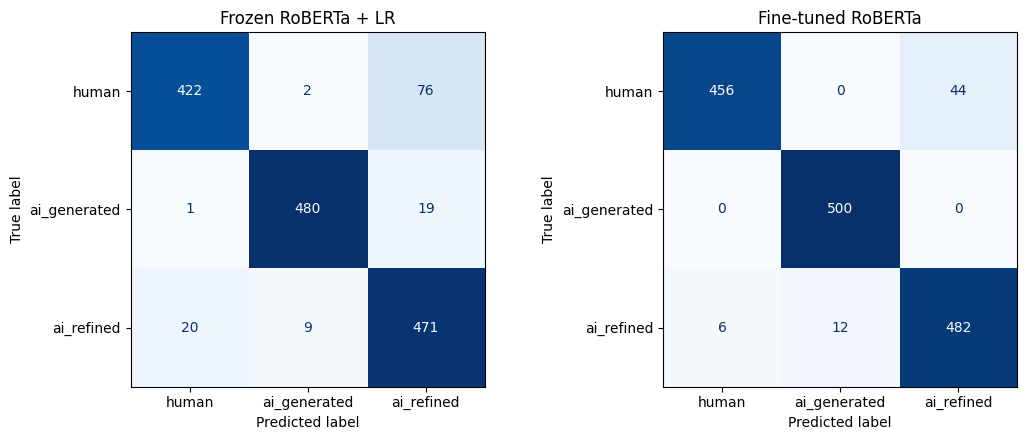

7. Confusion matrix change (fine-tuned − frozen; rows = true, columns = predicted)
   Diagonal > 0 means more texts correct; off-diagonal > 0 means more of that error.


,pred human,pred ai_generated,pred ai_refined
true human,34,-2,-32
true ai_generated,-1,20,-19
true ai_refined,-14,3,11


In [6]:
FZ, FT = 'Frozen RoBERTa + LR', 'Fine-tuned RoBERTa'

# ---- 1. overall ----
rows = {}
for name, col in [(FZ, 'pred_frozen'), (FT, 'pred_ft')]:
    rows[name] = {
        'accuracy': accuracy_score(y, cmp[col]),
        'macro_f1': f1_score(y, cmp[col], labels=LABELS, average='macro'),
        'errors': int((cmp[col] != cmp['label']).sum()),
    }
overall = pd.DataFrame(rows).T
overall.loc['Δ (fine-tuned − frozen)'] = overall.loc[FT] - overall.loc[FZ]
print('1. Overall')
display(overall.round(4).astype({'errors': 'int'}))

# ---- 2. per-class precision / recall / F1 ----
def per_class(col):
    p, r, f, _ = precision_recall_fscore_support(y, cmp[col], labels=LABELS, zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f}, index=LABELS)

pc_fz, pc_ft = per_class('pred_frozen'), per_class('pred_ft')
per_class_tbl = pd.concat({'frozen': pc_fz, 'fine-tuned': pc_ft, 'Δ (ft − frozen)': pc_ft - pc_fz}, axis=1)
per_class_tbl[('support', 'n')] = cmp['label'].value_counts().reindex(LABELS).to_numpy()
print('2. Per class')
display(per_class_tbl.round(4))

# ---- 3-6. accuracy sliced by metadata (for the by-label table this is recall) ----
def side_by_side(by):
    g = cmp.groupby(by, observed=True).agg(
        n=('ft_correct', 'size'), frozen_acc=('frozen_correct', 'mean'), ft_acc=('ft_correct', 'mean'))
    g['Δ (ft − frozen)'] = g['ft_acc'] - g['frozen_acc']
    return g.round(4)

if 'domain' in cmp.columns:
    print('3. Accuracy by domain')
    display(side_by_side('domain'))
    print('4. Accuracy by domain and true label')
    display(side_by_side(['domain', 'label']))
if 'model' in cmp.columns:
    print('5. Accuracy by source LLM')
    display(side_by_side('model'))

cmp['length_bucket'] = pd.qcut(cmp['n_words'], 4, duplicates='drop')
print('6. Accuracy by text length (quartiles of word count)')
display(side_by_side('length_bucket'))

# ---- 7. confusion matrices ----
cm_fz = confusion_matrix(y, cmp['pred_frozen'], labels=LABELS)
cm_ft = confusion_matrix(y, cmp['pred_ft'], labels=LABELS)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cm, title in [(axes[0], cm_fz, FZ), (axes[1], cm_ft, FT)]:
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

print('7. Confusion matrix change (fine-tuned − frozen; rows = true, columns = predicted)')
print('   Diagonal > 0 means more texts correct; off-diagonal > 0 means more of that error.')
display(pd.DataFrame(cm_ft - cm_fz, index=[f'true {l}' for l in LABELS],
                     columns=[f'pred {l}' for l in LABELS]))

In [7]:
# ---- 8. who is right when? ----
both = cmp['ft_correct'] & cmp['frozen_correct']
only_ft = cmp['ft_correct'] & ~cmp['frozen_correct']
only_fz = ~cmp['ft_correct'] & cmp['frozen_correct']
neither = ~cmp['ft_correct'] & ~cmp['frozen_correct']
neither_diff = neither & (cmp['pred_ft'] != cmp['pred_frozen'])

agreement = pd.DataFrame({
    'texts': [both.sum(), only_ft.sum(), only_fz.sum(), neither.sum(), neither_diff.sum()],
}, index=['both correct', 'only fine-tuned correct', 'only frozen correct',
          'both wrong', '  of which wrong in different ways'])
agreement['share'] = (agreement['texts'] / len(cmp)).round(4)
print('8. Agreement on correctness')
display(agreement)

# ---- 9. exact McNemar test on the discordant texts ----
b, c = int(only_ft.sum()), int(only_fz.sum())
p_mc = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
print(f'9. McNemar (exact): fine-tuned-only correct = {b}, frozen-only correct = {c}, p = {p_mc:.4g}')

if 'domain' in cmp.columns:
    def mcnemar_row(sub):
        b_ = int((sub['ft_correct'] & ~sub['frozen_correct']).sum())
        c_ = int((~sub['ft_correct'] & sub['frozen_correct']).sum())
        p_ = binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ > 0 else 1.0
        return pd.Series({'n': len(sub), 'only_ft_right': b_, 'only_frozen_right': c_, 'p_value': p_})
    print('   McNemar by domain (post-hoc slices; do not correct for multiple comparisons)')
    mc = pd.DataFrame({d: mcnemar_row(g) for d, g in cmp.groupby('domain')}).T
    mc[['n', 'only_ft_right', 'only_frozen_right']] = mc[['n', 'only_ft_right', 'only_frozen_right']].astype(int)
    mc['p_value'] = mc['p_value'].map(lambda v: f'{v:.3g}')
    display(mc)

# ---- 10. paired bootstrap, resampling whole pair_id groups ----
rng = np.random.default_rng(SEED)
p_ft, p_fz = cmp['pred_ft'].to_numpy(), cmp['pred_frozen'].to_numpy()
if 'pair_id' in cmp.columns:
    groups = list(cmp.groupby('pair_id').indices.values())
else:
    groups = [np.array([i]) for i in range(len(cmp))]

N_BOOT = 2000
acc_d, f1_d = np.empty(N_BOOT), np.empty(N_BOOT)
for i in range(N_BOOT):
    pick = rng.integers(0, len(groups), len(groups))
    idx = np.concatenate([groups[j] for j in pick])
    acc_d[i] = (p_ft[idx] == y[idx]).mean() - (p_fz[idx] == y[idx]).mean()
    f1_d[i] = (f1_score(y[idx], p_ft[idx], labels=LABELS, average='macro')
               - f1_score(y[idx], p_fz[idx], labels=LABELS, average='macro'))

obs = {'accuracy': (p_ft == y).mean() - (p_fz == y).mean(),
       'macro-F1': (f1_score(y, p_ft, labels=LABELS, average='macro')
                    - f1_score(y, p_fz, labels=LABELS, average='macro'))}
boot_tbl = pd.DataFrame({
    'observed Δ (ft − frozen)': [obs['accuracy'], obs['macro-F1']],
    'CI 2.5%': [np.percentile(acc_d, 2.5), np.percentile(f1_d, 2.5)],
    'CI 97.5%': [np.percentile(acc_d, 97.5), np.percentile(f1_d, 97.5)],
}, index=['accuracy', 'macro-F1']).round(4)
print(f'10. Paired bootstrap, {N_BOOT} resamples of {"pair_id groups" if "pair_id" in cmp.columns else "texts"}')
display(boot_tbl)
print('An interval that excludes 0 means the difference is unlikely to be test-set sampling noise. '
      'It does NOT cover training randomness: this is one fine-tuning run and one LR fit, so repeat '
      'with other seeds before claiming a robust gap.')

8. Agreement on correctness


,texts,share
both correct,1341,0.8940
only fine-tuned correct,97,0.0647
only frozen correct,32,0.0213
both wrong,30,0.0200
of which wrong in different ways,1,0.0007


9. McNemar (exact): fine-tuned-only correct = 97, frozen-only correct = 32, p = 8.499e-09
   McNemar by domain (post-hoc slices; do not correct for multiple comparisons)


,n,only_ft_right,only_frozen_right,p_value
Academic,750,21,15,0.405
Wiki,750,76,17,4.45e-10


10. Paired bootstrap, 2000 resamples of pair_id groups


,observed Δ (ft − frozen),CI 2.5%,CI 97.5%
accuracy,0.0433,0.0300,0.0587
macro-F1,0.0428,0.0296,0.0579


An interval that excludes 0 means the difference is unlikely to be test-set sampling noise. It does NOT cover training randomness: this is one fine-tuning run and one LR fit, so repeat with other seeds before claiming a robust gap.


In [8]:
# ---- 11. texts the two approaches label differently ----
EXAMPLES_PER_LABEL = 2     # examples per (outcome, true label) group
EXAMPLE_SEED = 0           # change to see different samples
MAX_CHARS = 700            # characters of text shown per example
SHOW_FULL_TEXT = False

DUP_START = re.compile(r'^\s*"?(.{3,100}?)"?\s+"?\1"?(?=\s|$)')
cmp['dup_title'] = cmp['text'].map(lambda t: bool(DUP_START.match(t)))
cmp['markdown'] = cmp['text'].str.contains(r'[*#`]', regex=True)

cmp['disagree'] = cmp['pred_ft'] != cmp['pred_frozen']
cmp['outcome'] = np.select(
    [cmp['ft_correct'] & ~cmp['frozen_correct'], ~cmp['ft_correct'] & cmp['frozen_correct']],
    ['fine-tuned right, frozen wrong', 'frozen right, fine-tuned wrong'],
    default='both wrong (different labels)')
dis = cmp[cmp['disagree']].copy()
print(f'11. {len(dis)} of {len(cmp)} texts ({len(dis) / len(cmp):.1%}) get different labels from the two approaches\n')

print('Outcome of the disagreements')
display(dis['outcome'].value_counts().to_frame('texts'))

print('How labels move: rows = frozen prediction, columns = fine-tuned prediction (all test texts)')
display(pd.crosstab(cmp['pred_frozen'], cmp['pred_ft']).reindex(index=LABELS, columns=LABELS, fill_value=0))

print('Disagreements by true label')
display(pd.crosstab(dis['label'], dis['outcome']))
if 'domain' in dis.columns:
    print('Disagreements by domain')
    display(pd.crosstab(dis['domain'], dis['outcome']))
if 'model' in dis.columns:
    print('Disagreements by source LLM')
    display(pd.crosstab(dis['model'], dis['outcome']))

def profile(df):
    agg = {'texts': ('text', 'size'), 'mean_words': ('n_words', 'mean'),
           'share_dup_title': ('dup_title', 'mean'), 'share_markdown': ('markdown', 'mean')}
    if 'ft_confidence' in df.columns:
        agg['ft_confidence'] = ('ft_confidence', 'mean')
    return agg

prof = dis.groupby('outcome').agg(**profile(dis))
all_row = cmp.assign(outcome='all test texts').groupby('outcome').agg(**profile(cmp))
print('Profile of disagreement groups vs all test texts (formatting cues and length)')
display(pd.concat([prof, all_row]).round(3))

def show_examples(group_df, title):
    print('\n' + '=' * 110)
    print(f'{title.upper()}  ({len(group_df)} texts)')
    print('=' * 110)
    for label in LABELS:
        sub = group_df[group_df['label'] == label]
        if sub.empty:
            continue
        for _, r in sub.sample(min(EXAMPLES_PER_LABEL, len(sub)), random_state=EXAMPLE_SEED).iterrows():
            conf = f" | fine-tuned confidence {r['ft_confidence']:.2f}" if 'ft_confidence' in r.index else ''
            print(f"\n[true: {r['label']}]  frozen -> {r['pred_frozen']}   fine-tuned -> {r['pred_ft']}{conf}")
            meta = ' | '.join(str(r[c]) for c in ['domain', 'model', 'pair_id'] if c in r.index)
            if meta:
                print(meta)
            text = r['text'] if SHOW_FULL_TEXT else r['text'][:MAX_CHARS] + (' ...' if len(r['text']) > MAX_CHARS else '')
            print(textwrap.fill(text.replace('\n', ' <newline> '), width=110))

for outcome_name in ['fine-tuned right, frozen wrong', 'frozen right, fine-tuned wrong',
                     'both wrong (different labels)']:
    show_examples(dis[dis['outcome'] == outcome_name], outcome_name)

# ---- save everything for the report ----
cmp_path = f'comparison_finetuned_vs_frozen_len{MAX_LENGTH}.csv'
dis_path = f'disagreements_finetuned_vs_frozen_len{MAX_LENGTH}.csv'
cmp.drop(columns=['length_bucket']).to_csv(cmp_path, index=False)
dis.drop(columns=['length_bucket']).to_csv(dis_path, index=False)
print(f'\nSaved {cmp_path} and {dis_path}')
try:
    from google.colab import files
    files.download(dis_path)
except ImportError:
    pass

11. 130 of 1500 texts (8.7%) get different labels from the two approaches

Outcome of the disagreements


,texts
outcome,
"fine-tuned right, frozen wrong",97
"frozen right, fine-tuned wrong",32
both wrong (different labels),1


How labels move: rows = frozen prediction, columns = fine-tuned prediction (all test texts)


pred_ft,human,ai_generated,ai_refined
pred_frozen,,,
human,405,1,37
ai_generated,1,483,7
ai_refined,56,28,482


Disagreements by true label


outcome,both wrong (different labels),"fine-tuned right, frozen wrong","frozen right, fine-tuned wrong"
label,,,
ai_generated,0,20,0
ai_refined,0,24,13
human,1,53,19


... (5 outputs left out)

,texts,mean_words,share_dup_title,share_markdown,ft_confidence
outcome,,,,,
both wrong (different labels),1,277.000,0.000,0.000,0.969
"fine-tuned right, frozen wrong",97,269.186,0.052,0.000,0.991
"frozen right, fine-tuned wrong",32,279.344,0.000,0.000,0.906
all test texts,1500,276.919,0.060,0.074,0.996



FINE-TUNED RIGHT, FROZEN WRONG  (97 texts)

[true: human]  frozen -> ai_refined   fine-tuned -> human | fine-tuned confidence 1.00
Wiki | qwen-max | 38916
XX Persei (IRC +50052 / HIP 9582 / BD+54°444) is a semiregular variable red supergiant star in the
constellation Perseus, between the Double Cluster and the border with Andromeda. Variability XX Persei is a
semiregular variable star of sub-type SRc, indicating a cool supergiant. The General Catalogue of Variable
Stars gives the period as 415 days. It also shows a long secondary period which was originally given at 4,100
days. A more recent study shows only slow variations with a period of 3,150 ± 1,000 days. Another study failed
to find any long period up to 10,000 days. Distance The most likely distance of XX Per is , from assumed
membership of the Perseus OB1 association. Gaia Data Release ...

[true: human]  frozen -> ai_refined   fine-tuned -> human | fine-tuned confidence 1.00
Wiki | qwen-max | 38776
Sir John Archibald Browne G

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes

- **Method:** full fine-tuning of `roberta-base` (all weights updated), LR 2e-5, 3 epochs, batch 16, 10% warmup, weight decay 0.01, fp16; best epoch chosen by validation macro-F1; test split evaluated once.
- **Fine-tuned vs frozen (same max length):** report the paired deltas with the McNemar p-value and bootstrap interval from section 10, and use the disagreement examples to illustrate what fine-tuning changes.
- **Shortcut check:** report the macro-F1 change from section 8 and the per-class pattern rates.
- **Limitations:** 512-token truncation, a test split that may not cover unseen LLMs or domains, and a small training set (about 5,100 texts).